In [1]:
 #import neccesarry Libraries
import numpy as np
import yfinance as yf
import pandas as pd
import math as ma
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata


In [2]:
def load_two_stocks(ticker1, ticker2, start='2020-10-01', end='2025-10-31'):
    df1 = yf.download(ticker1, start=start, end=end, auto_adjust=False)
    df2 = yf.download(ticker2, start=start, end=end, auto_adjust=False)
    adj_close_1 = df1['Adj Close']
    adj_close_2 = df2['Adj Close']

    # Daily returns
    Stock_1_Daily_returns = adj_close_1.pct_change().dropna()
    Stock_2_Daily_returns = adj_close_2.pct_change().dropna()

        # Average daily return
    Stock_1_Average_Daily_Returns = float(Stock_1_Daily_returns.mean())
    Stock_2_Average_Daily_Returns = float(Stock_2_Daily_returns.mean())

    # Expected return over 3 years (approx. 252 trading days per year)
    Expected_Stock_1_Returns = Stock_1_Average_Daily_Returns * len(Stock_1_Daily_returns)
    Expected_Stock_2_Returns = Stock_2_Average_Daily_Returns* len(Stock_2_Daily_returns)

    SD1 = float(Stock_1_Daily_returns.std()*ma.sqrt( len(Stock_1_Daily_returns)))   
    SD2 = float(Stock_2_Daily_returns.std()*ma.sqrt(len(Stock_2_Daily_returns)))

    daily_returns = pd.concat([Stock_1_Daily_returns, Stock_2_Daily_returns], axis=1)
    covariance_matrix = daily_returns.cov()
    correlation_matrix = daily_returns.corr()
    covariance = correlation_matrix.loc[ticker1,ticker2] * SD1 *SD2


    return SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2

def Optimal_Weights(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2):

    Stock_1_Weight=((SD2)**2 -covariance)/((SD1)**2 + (SD2)**2 -2*(covariance))
    Stock_1_Weight_calibrated= max(0, min(1, Stock_1_Weight))

    Stock_2_Weight=1-Stock_1_Weight_calibrated

    Portfolio_Returns=Stock_1_Weight_calibrated*(Expected_Stock_1_Returns)+Stock_2_Weight*(Expected_Stock_2_Returns)

    Portfolio_SD=ma.sqrt((Stock_1_Weight_calibrated**2)*((SD1)**2)+(Stock_2_Weight**2)*((SD2)**2) + 2*Stock_1_Weight_calibrated*Stock_2_Weight*covariance)
    
    #Risk Free Rate=0
    Sharpe_Ratio=Portfolio_Returns/Portfolio_SD
    #####################################################
    labels = [ticker1,ticker2]
    weights = [Stock_1_Weight_calibrated, Stock_2_Weight]
    colors = ["#0EA2E6", "#F0A40D"]

    plt.figure(figsize=(7,7))
    wedges, texts, autotexts = plt.pie(
        weights,
        labels=labels,
        autopct='%1.1f%%',
        startangle=80,
        colors=colors,
        shadow=True,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )

    # Beautify text
    for text in texts:
        text.set_fontsize(14)
        text.set_fontweight('bold')
    for autotext in autotexts:
        autotext.set_fontsize(13)
        autotext.set_color('black')
        autotext.set_fontweight('bold')

    plt.title("Minimum-Risk Portfolio Allocation", fontsize=17, fontweight='bold')
    plt.text(-1.5, -1.2, 
         f"Expected 3Y Return: {Portfolio_Returns:.2%}\n"
         f"Portfolio Risk: {Portfolio_SD:.2%}\n"
         f"Sharpe Ratio: {Sharpe_Ratio:.2f}",
         fontsize=12,
         fontweight='bold',
         ha='left',
         va='top',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray', boxstyle='round,pad=0.5'))
    plt.show()
    print('Minimum-Risk Optimal Portfolio:')
    print(f"The optimal weight for {ticker1} is ({Stock_1_Weight_calibrated*100:.1f}%).")
    print(f"The optimal weight for {ticker2} is ({Stock_2_Weight*100:.1f}%).")
    print(f"The expected annual return of the portfolio is {Portfolio_Returns:.2%}.")
    print(f"The annualized portfolio standard deviation (risk) is {Portfolio_SD:.2%}.")
    print(f"The Sharpe ratio of the portfolio is {Sharpe_Ratio:.2f}.")
    print("##########################################################################")

    return Stock_1_Weight_calibrated,Stock_2_Weight,Portfolio_Returns,Portfolio_SD,Sharpe_Ratio






In [3]:
#Finding Max Sharpe Ratio with portfolio weight allocation
def Max_Sharpe(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2):
    weight_values = np.linspace(0, 1, 100)
    generated_portfolio_returns = []
    generated_portfolio_std = []
    generated_weights = []

    for weight_1 in weight_values:
        weight_2 = 1 - weight_1
        
        # Portfolio expected return (weighted average)
        portfolio_return = weight_1 * Expected_Stock_1_Returns + weight_2 * Expected_Stock_2_Returns
        
        # Portfolio standard deviation (with correlation)
        portfolio_std = np.sqrt(
            (weight_1**2) * (SD1**2) +
            (weight_2**2) * (SD2**2) +
            2 * weight_1 * weight_2 * covariance
        )
        
        generated_portfolio_returns.append(portfolio_return)
        generated_portfolio_std.append(portfolio_std)
        generated_weights.append([weight_1, weight_2])

    # Convert to arrays for easier plotting
    returns = np.array(generated_portfolio_returns)
    stds = np.array(generated_portfolio_std)
    ################################################################################################################
    risk_free_rate=0
    Sharpe_ratios = (np.array(generated_portfolio_returns) - risk_free_rate) / np.array(generated_portfolio_std)
    max_SR_index = np.argmax(Sharpe_ratios)
    max_sharpe_value=Sharpe_ratios[max_SR_index]
    max_sharpe_return = returns[max_SR_index]
    max_sharpe_std = stds[max_SR_index]

    print('Maximum Sharpe Ratio Portfolio:')
    print(f"Expected Return at Max Sharpe: {max_sharpe_return:.2f}({max_sharpe_return*100:.2f}%)")
    print(f"Standard Deviation (Risk) at Max Sharpe: {max_sharpe_std:.2f}({max_sharpe_std*100:.2f}%)")
    #Max Sharpe means highest expected return with least amount of risk 
    print(f'The Sharpe ratio of the portfolio is {max_sharpe_value:.3f}')
    #portflio weights
    weight_for_max_sharpe=generated_weights[max_SR_index]
    q1, q2 = weight_for_max_sharpe
    print(f'The weights for Max Sharpe Ratio are {ticker1}:{q1*100:.2f}% , {ticker2}:{q2*100:.2f}%')
    #################################################################################################################
    #Plotting the Pie-chart
    labels = [ticker1,ticker2]
    weights = [q1, q2]
    colors = ["#FFF200", "#1F6CDF"]

    plt.figure(figsize=(7,7))
    wedges, texts, autotexts = plt.pie(
        weights,
        labels=labels,
        autopct='%1.1f%%',
        startangle=80,
        colors=colors,
        shadow=True,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )

    # Beautify text
    for text in texts:
        text.set_fontsize(14)
        text.set_fontweight('bold')
    for autotext in autotexts:
        autotext.set_fontsize(13)
        autotext.set_color('black')
        autotext.set_fontweight('bold')

    plt.title("Max Sharpe Portfolio", fontsize=17, fontweight='bold')
    plt.text(-1.5, -1.2, 
         f"Expected 3Y Return: {max_sharpe_return:.2%}\n"
         f"Portfolio Risk: {max_sharpe_std:.2%}\n"
         f"Sharpe Ratio: {max_sharpe_value:.2f}",
         fontsize=12,
         fontweight='bold',
         ha='left',
         va='top',
         bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray', boxstyle='round,pad=0.5'))
    plt.show()
    print('Max Sharpe Portfolio:')
    print(f"The optimal weight for {ticker1} is ({q1*100:.1f}%).")
    print(f"The optimal weight for {ticker2} is ({q2*100:.1f}%).")
    print(f"The expected annual return of the portfolio is {max_sharpe_return:.2%}.")
    print(f"The annualized portfolio standard deviation (risk) is {max_sharpe_std:.2%}.")
    print(f"The Sharpe ratio of the portfolio is {max_sharpe_value:.2f}.")
    print("##########################################################################")


    # Plot the efficient frontier
    plt.figure(figsize=(10, 6))
    plt.scatter(stds, returns, c=returns/stds, cmap='viridis',s=10, label='Portfolios')
    plt.colorbar(label='Sharpe Ratio')
    plt.scatter(SD1, Expected_Stock_1_Returns, c='red', s=20, label=f'{ticker1}')
    plt.scatter(SD2, Expected_Stock_2_Returns, c='blue', s=20, label=f'{ticker2}')
    plt.scatter(stds[max_SR_index], returns[max_SR_index], marker='8', c='gold', s=50, edgecolors='black', label='Max Sharpe Portfolio')
    plt.xlabel('Portfolio Standard Deviation (Risk)')
    plt.ylabel('Portfolio Expected Return')
    plt.title(f'Two-Asset Efficient Frontier: {ticker1} vs {ticker2}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    
    return


In [4]:
def Max_Sharpe_3D(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2):
    weight_values = np.linspace(0, 1, 100)
    generated_portfolio_returns = []
    generated_portfolio_std = []
    generated_weights = []

    for weight_1 in weight_values:
        weight_2 = 1 - weight_1
        
        # Portfolio expected return (weighted average)
        portfolio_return = weight_1 * Expected_Stock_1_Returns + weight_2 * Expected_Stock_2_Returns
        
        # Portfolio standard deviation (with correlation)
        portfolio_std = np.sqrt(
            (weight_1**2) * (SD1**2) +
            (weight_2**2) * (SD2**2) +
            2 * weight_1 * weight_2 * covariance
        )
        
        generated_portfolio_returns.append(portfolio_return)
        generated_portfolio_std.append(portfolio_std)
        generated_weights.append([weight_1, weight_2])

    # Convert to arrays for easier plotting
    returns = np.array(generated_portfolio_returns)
    stds = np.array(generated_portfolio_std)
    ################################################################################################################
    risk_free_rate=0
    Sharpe_ratios = (np.array(generated_portfolio_returns) - risk_free_rate) / np.array(generated_portfolio_std)
    max_SR_index = np.argmax(Sharpe_ratios)
    max_sharpe_value=Sharpe_ratios[max_SR_index]
    #Max Sharpe means highest expected return with least amount of risk 

    #print(f'The Sharpe ratio of the portfolio is {max_sharpe_value}')
    #portflio weights
    weight_for_max_sharpe=generated_weights[max_SR_index]
    q1, q2 = weight_for_max_sharpe
    #print(f'The weights for Max Sharpe Ratio are {ticker1}:{q1} , {ticker2}:{q2}')


    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Create a grid for interpolation
    grid_std = np.linspace(min(stds), max(stds), 500)
    grid_return = np.linspace(min(returns), max(returns), 500)
    grid_std, grid_return = np.meshgrid(grid_std, grid_return)
    # Interpolate Sharpe ratios on the grid
    grid_sharpe = griddata((stds, returns), Sharpe_ratios, (grid_std, grid_return), method='cubic')

    # Plot surface
    surf = ax.plot_surface(grid_std, grid_return, grid_sharpe, cmap='viridis', alpha=0.65, edgecolor='none')

    # Scatter points for actual portfolios
    sc = ax.scatter(stds, returns, Sharpe_ratios, c=Sharpe_ratios, cmap='viridis', s=20)

    # Highlight max Sharpe portfolio
    ax.scatter(stds[max_SR_index], returns[max_SR_index], Sharpe_ratios[max_SR_index],
               marker='8', c='gold', s=50, edgecolors='black', label='Max Sharpe Portfolio')

    ax.set_xlabel('Portfolio Risk (Std Dev)')
    ax.set_ylabel('Expected Return')
    ax.set_zlabel('Sharpe Ratio')
    ax.set_title(f'3D Portfolio Surface: {ticker1} vs {ticker2}')

    # Color bar
    cbar = plt.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
    cbar.set_label('Sharpe Ratio')
    ax.legend()
    plt.show()
    return

    



In [5]:
#Funciton to run through all functions
def call_1(name1,name2):
    SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2=load_two_stocks(name1,name2)
    Stock_1_Weight,Stock_2_Weight,Portfolio_Returns,Portfolio_SD,Sharpe_Ratio=Optimal_Weights(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2)
    return


In [6]:
def call_2D(name1,name2):
    #2D Efficient Frontier 
    SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2=load_two_stocks(name1,name2)
    Max_Sharpe(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2)
    return 


In [7]:
def call_3D(name1,name2):
    #3D Efficient Frontier 
    SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2=load_two_stocks(name1,name2)
    Max_Sharpe_3D(SD1,SD2,covariance,Expected_Stock_1_Returns,Expected_Stock_2_Returns,ticker1,ticker2)
    return

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_1_Average_Daily_Returns = float(Stock_1_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_2_Average_Daily_Returns = float(Stock_2_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:19: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  SD1 = float(Stock_1_Daily_returns.std()*ma.sqrt( len(Stock_1_Daily_returns)))
C:\Users\

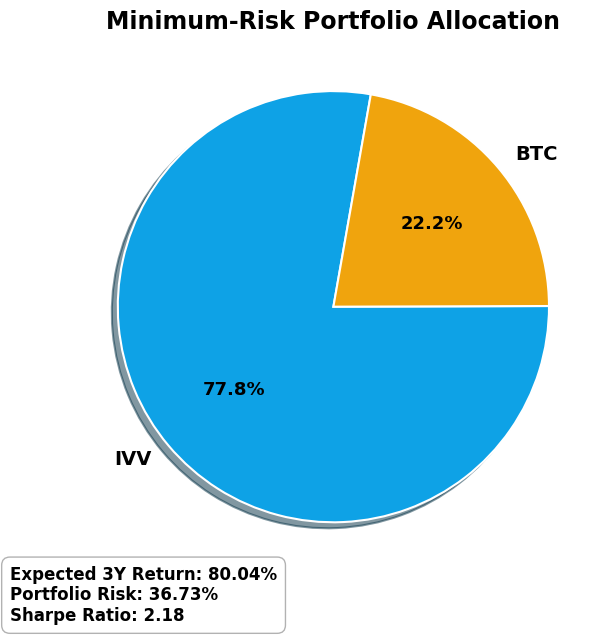

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Minimum-Risk Optimal Portfolio:
The optimal weight for IVV is (77.8%).
The optimal weight for BTC is (22.2%).
The expected annual return of the portfolio is 80.04%.
The annualized portfolio standard deviation (risk) is 36.73%.
The Sharpe ratio of the portfolio is 2.18.
##########################################################################
Maximum Sharpe Ratio Portfolio:
Expected Return at Max Sharpe: 0.83(83.35%)
Standard Deviation (Risk) at Max Sharpe: 0.37(37.49%)
The Sharpe ratio of the portfolio is 2.223
The weights for Max Sharpe Ratio are IVV:92.93% , BTC:7.07%



C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_1_Average_Daily_Returns = float(Stock_1_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_2_Average_Daily_Returns = float(Stock_2_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:19: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  SD1 = float(Stock_1_Daily_returns.std()*ma.sqrt( len(Stock_1_Daily_returns)))
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:20: FutureWarning: Calling float on a single element Series is deprecated and will

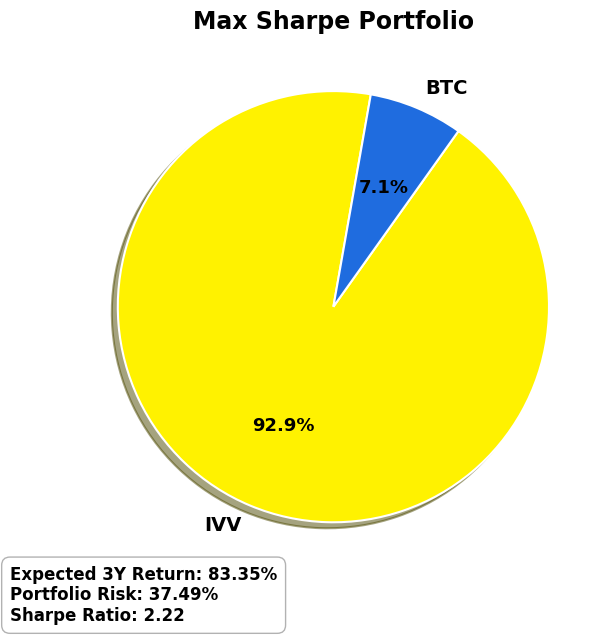

Max Sharpe Portfolio:
The optimal weight for IVV is (92.9%).
The optimal weight for BTC is (7.1%).
The expected annual return of the portfolio is 83.35%.
The annualized portfolio standard deviation (risk) is 37.49%.
The Sharpe ratio of the portfolio is 2.22.
##########################################################################


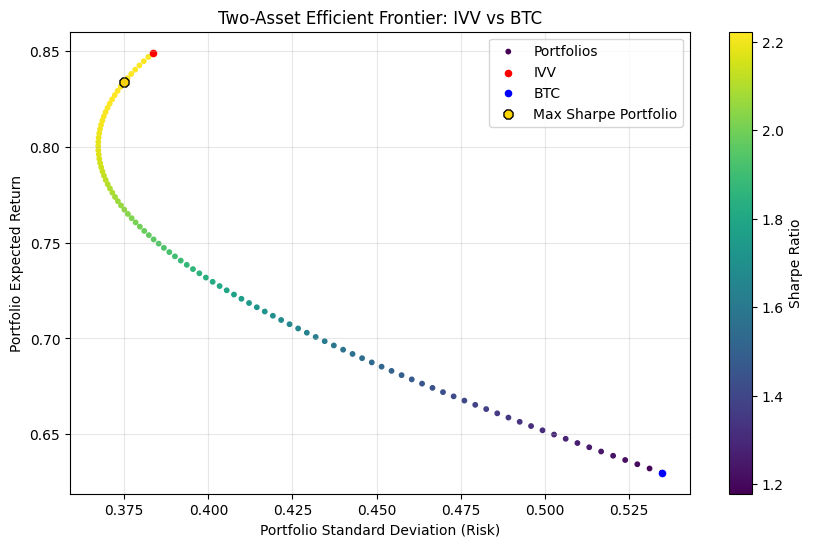

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_1_Average_Daily_Returns = float(Stock_1_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Stock_2_Average_Daily_Returns = float(Stock_2_Daily_returns.mean())
C:\Users\Admin\AppData\Local\Temp\ipykernel_13484\2250180892.py:19: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  SD1 = float(Stock_1_Daily_returns.std()*ma.sqrt( len(Stock_1_Daily_returns)))
C:\Users\

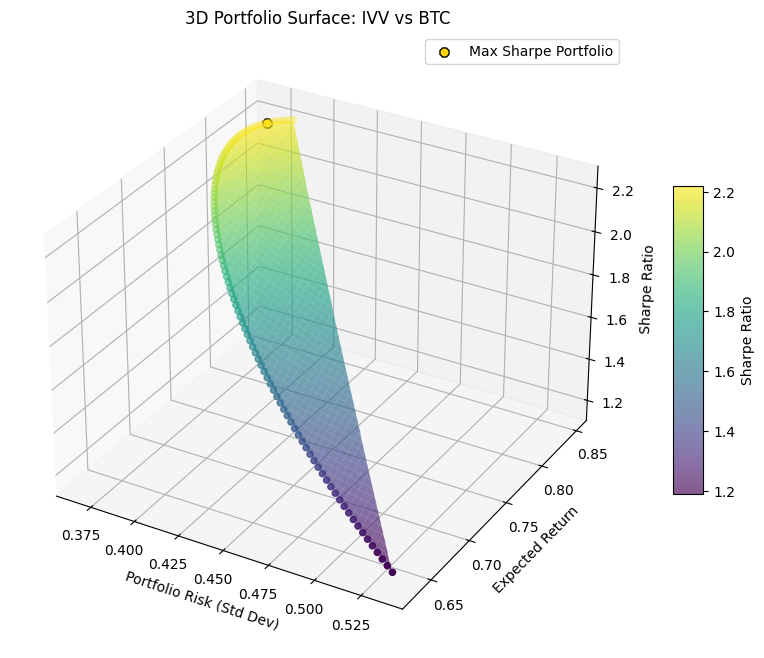

In [8]:
def call_all(name1,name2):
    call_1(name1,name2)
    call_2D(name1,name2)
    call_3D(name1,name2)
    return
call_all('IVV','BTC')   